# Extension: best strategies per opponent strength
The main analysis (`results.ipynb`) finds the best 4th-down strategy against an **equal** opponent. Here we repeat steps 1 and 2 against a **weak** and a **strong** opponent (plays drawn only from the bottom / top third of teams by EPA per play), with the same candidates (7,392), field-goal range (57 yards) and rule parameters, so the three are comparable.

Computed by `opponents_compute.py` (about 40 minutes), saved in `results_opponents.json`. All gains are in percentage points of win probability **over real coaches facing the same opponent**.

In [1]:
import pandas as pd
import model as M
import plots_opponents as PO

r = M.load_results("results_opponents.json")
OPPS = PO.OPPS

def row(o):
    f = r[f"{o}/final"]
    single = f.loc[f"Best single rule (X = {r[f'{o}/best_x']})"]
    best, eq = f.loc[r[f"{o}/best_name"]], f.loc[r[f"{o}/equal_winner"]]
    return {"coaches win": r[f"{o}/singles"].loc["1. Real coaches", "p̂"],
            "best single rule": f"go if ≤ {r[f'{o}/best_x']} yd: {single['diff (pp)']:+.2f} [{single['diff lower']:+.2f}, {single['diff upper']:+.2f}]",
            "best combination": r[f"{o}/best_name"],
            "its gain": f"{best['diff (pp)']:+.2f} [{best['diff lower']:+.2f}, {best['diff upper']:+.2f}]",
            "equal-opponent winner's gain": f"{eq['diff (pp)']:+.2f} [{eq['diff lower']:+.2f}, {eq['diff upper']:+.2f}]"}

pd.set_option("display.max_colwidth", None)
pd.DataFrame({o: row(o) for o in OPPS})

,weak,equal,strong
coaches win,0.657167,0.501117,0.349867
best single rule,"go if ≤ 6 yd: +2.48 [+2.11, +2.85]","go if ≤ 6 yd: +4.21 [+3.79, +4.62]","go if ≤ 6 yd: +5.27 [+4.89, +5.65]"
best combination,≤4 yd (≤1 yd inside own 30) + no man's land 35–55 (≤6 yd) + goal line + trailing (≤2 drives) + protect lead (≤3 drives) | else kick,≤4 yd (≤1 yd inside own 30) + no man's land 35–55 (≤6 yd) + goal line + trailing (≤2 drives) + protect lead (≤3 drives) | else kick,≤6 yd (≤1 yd inside own 30) + trailing (≤3 drives) + protect lead (≤3 drives) | else coach
its gain,"+3.52 [+3.15, +3.89]","+4.62 [+4.21, +5.03]","+5.61 [+5.24, +5.97]"
equal-opponent winner's gain,"+3.52 [+3.15, +3.89]","+4.62 [+4.21, +5.03]","+5.35 [+4.97, +5.73]"


## Step 1: each single strategy against each opponent (30,000 paired games)

In [2]:
pd.DataFrame({o: r[f"{o}/singles"]["diff (pp)"].values for o in OPPS},
             index=[s.split(' (')[0] for s in r["equal/singles"].index]).round(2)

,weak,equal,strong
1. Real coaches,0.00,0.00,0.00
2. Never,-3.84,-3.56,-3.78
3. Always,-5.55,-2.44,0.48
4. Fixed rate,-4.20,-3.79,-2.64
5. Short yardage,2.26,4.19,5.48
6. Past midfield,-0.23,0.89,1.25
7. Short and close,2.26,4.19,5.48
8. No man's land,-3.60,-3.26,-3.12
9. Goal line,-2.89,-2.46,-2.68
10. Trailing late,-0.21,0.58,1.67


## Step 2: best combination per opponent (successive halving, then 50,000 fresh paired games)
Each opponent's own top 5 next to the equal-opponent winner and the best single rule; the best one wins.

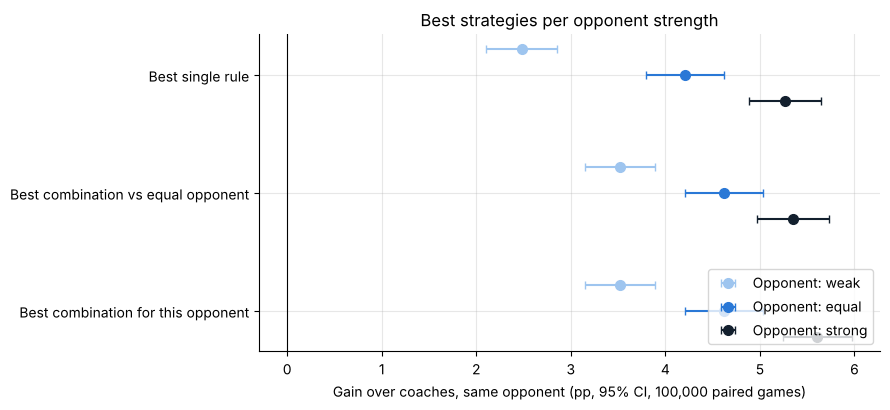

In [3]:
PO.summary(r)

In [5]:
for o in OPPS:
    display(r[f"{o}/final"][["p̂", "diff (pp)", "diff lower", "diff upper", "go %"]].round(3).rename_axis(o))

,p̂,diff (pp),diff lower,diff upper,go %
weak,,,,,
≤3 yd + no man's land 35–55 (≤6 yd) + goal line + trailing (≤2 drives) + protect lead (≤3 drives) | else coach,0.690,3.358,3.018,3.699,41.730
≤3 yd + no man's land 35–55 (≤6 yd) + goal line + trailing (≤2 drives) | else coach,0.691,3.377,3.037,3.717,45.539
≤4 yd + no man's land 35–55 (≤6 yd) + goal line + trailing (≤2 drives) | else coach,0.691,3.377,3.028,3.726,50.431
≤3 yd + no man's land 35–55 (≤6 yd) + trailing (≤2 drives) + protect lead (≤3 drives) | else coach,0.689,3.241,2.901,3.581,41.094
≤3 yd + no man's land 35–55 (≤6 yd) + trailing (≤2 drives) | else coach,0.689,3.256,2.917,3.596,44.808
≤4 yd (≤1 yd inside own 30) + no man's land 35–55 (≤6 yd) + goal line + trailing (≤2 drives) + protect lead (≤3 drives) | else kick,0.692,3.522,3.153,3.891,42.455
Best single rule (X = 6),0.682,2.481,2.108,2.854,56.793


,p̂,diff (pp),diff lower,diff upper,go %
equal,,,,,
≤4 yd + no man's land 35–55 (≤6 yd) + goal line + trailing (≤2 drives) + protect lead (≤3 drives) | else kick,0.549,4.756,4.346,5.166,47.846
≤5 yd + no man's land 35–55 (≤6 yd) + trailing (≤2 drives) | else kick,0.546,4.394,3.983,4.806,55.762
≤4 yd + no man's land 35–55 (≤6 yd) + goal line + trailing (≤2 drives) | else kick,0.549,4.740,4.329,5.150,50.659
≤5 yd + no man's land 35–55 (≤6 yd) + trailing (≤2 drives) + protect lead (≤3 drives) | else kick,0.546,4.439,4.027,4.851,52.592
≤4 yd + no man's land 35–55 (≤6 yd) + goal line + trailing (≤3 drives) + protect lead (≤3 drives) | else kick,0.549,4.719,4.309,5.129,50.347
≤4 yd (≤1 yd inside own 30) + no man's land 35–55 (≤6 yd) + goal line + trailing (≤2 drives) + protect lead (≤3 drives) | else kick,0.548,4.622,4.213,5.030,45.503
Best single rule (X = 6),0.544,4.205,3.794,4.616,56.724


,p̂,diff (pp),diff lower,diff upper,go %
strong,,,,,
≤8 yd + trailing (≤2 drives) + protect lead (≤3 drives) | else kick,0.406,5.520,5.136,5.903,70.896
≤8 yd + trailing (≤2 drives) | else kick,0.404,5.412,5.029,5.796,73.721
≤6 yd + trailing (≤3 drives) + protect lead (≤3 drives) | else coach,0.406,5.596,5.228,5.963,62.504
≤8 yd + trailing (≤3 drives) + protect lead (≤3 drives) | else kick,0.404,5.390,5.007,5.774,72.584
≤6 yd & pos ≤85 + no man's land 35–55 (≤10 yd) + trailing (≤2 drives) + protect lead (≤3 drives) | else coach,0.405,5.501,5.130,5.872,64.452
≤4 yd (≤1 yd inside own 30) + no man's land 35–55 (≤6 yd) + goal line + trailing (≤2 drives) + protect lead (≤3 drives) | else kick,0.404,5.350,4.970,5.729,48.348
Best single rule (X = 6),0.403,5.268,4.887,5.649,56.673
≤6 yd (≤1 yd inside own 30) + trailing (≤3 drives) + protect lead (≤3 drives) | else coach,0.406,5.607,5.242,5.972,59.433


## The handbook against each opponent
The best combination's call on every 4th down in a normal situation (tied game, not late). Where a strategy falls back to the coaches, the map shows the coaches' most common call.

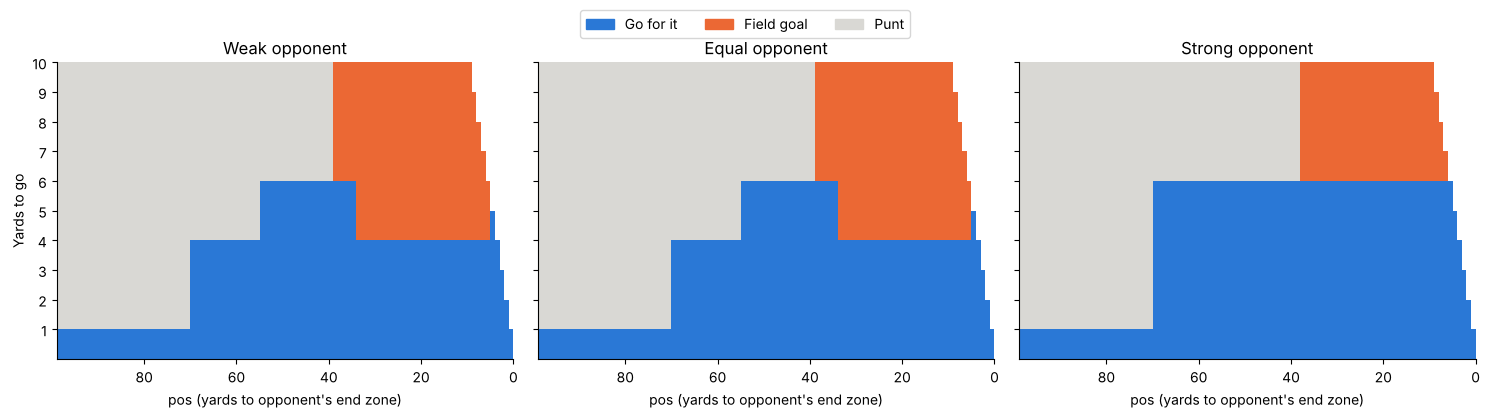

In [6]:
m = M.estimate(M.load_data())
PO.handbooks(r, m, M.load_results("results.json")["fg_range"])